<a href="https://colab.research.google.com/github/chrismji/Datasci-and-Ai-in-Bus/blob/main/HW4_TelcoChurn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting MegaTelCo Churn

After discussing the churn problem at TelCo with Nadia for a while (remember her?), you've finally defined an adequate target variable for churn and gathered relevant data to predict it. Moreover, the marketing department has come up with an amazing retention offer: the offer is guaranteed to convince customers to extend their contract for an extra year after receiving it. Unfortunately, the offer is quite expensive; it costs $200. __You have enough budget to give the retention offer to up to 25% of the customers whose contracts are expiring.__

It is your job to use data from previous contract expirations to build a churn predictive model and make a recommendation of whom to target with the offers. You have assembled the best historical data set you can at this point, which includes:

- Gender: Whether the customer is a male or a female
- SeniorCitizen: Whether the customer is a senior citizen or not (1, 0)
- Partner: Whether the customer has a partner or not (Yes, No)
- Dependents: Whether the customer has dependents or not (Yes, No)
- Tenure: Number of months the customer has stayed with the company
- PhoneService: Whether the customer has a phone service or not (Yes, No)
- MultipleLines: Whether the customer has multiple lines or not (Yes, No, No phone service)
- InternetService: Customer’s internet service provider (DSL, Fiber optic, No)
- OnlineSecurity: Whether the customer has online security or not (Yes, No, No internet service)
- OnlineBackup: Whether the customer has online backup or not (Yes, No, No internet service)
- DeviceProtection: Whether the customer has device protection or not (Yes, No, No internet service)
- TechSupport: Whether the customer has tech support or not (Yes, No, No internet service)
- StreamingTV: Whether the customer has streaming TV or not (Yes, No, No internet service)
- StreamingMovies: Whether the customer has streaming movies or not (Yes, No, No internet service)
- Contract: The contract term of the customer (Month-to-month, One year, Two year)
- PaperlessBilling: Whether the customer has paperless billing or not (Yes, No)
- PaymentMethod: The customer’s payment method (Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic))
- MonthlyCharges: The amount charged to the customer monthly
- Churn: Whether the customer churned or not shortly after contract expiration (Yes or No)

In [4]:
#load important packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree



In [5]:
import warnings
warnings.filterwarnings("ignore")

**1. Load the churn data [click here to download data](https://drive.google.com/uc?download&id=1xMMPIFOooEzcrdDFNFYvId5aROmTuzxv):**

**Use `get_dummies` to transform the categorical features into dummy features. (use `drop_first=True`)**

In [6]:
df = pd.read_csv('telco_churn.csv')
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,Yes


In [7]:
df = pd.get_dummies(df, drop_first=True, dtype=int)
df.head()

,SeniorCitizen,tenure,MonthlyCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,...,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,0,1,29.85,0,1,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
1,0,34,56.95,1,0,0,1,0,0,0,...,0,0,0,1,0,0,0,0,1,0
2,0,2,53.85,1,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,1
3,0,45,42.30,1,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
4,0,2,70.70,0,0,0,1,0,0,1,...,0,0,0,0,0,1,0,1,0,1


__2. _Of course_ normally we would do some detailed exploratory work!  But we have high confidence in the data quality and there are no missing values, so lets proceed. `Tenure` is often a key churn feature.  Make a plot to gain insight the relationship between Tenure and probability of Churn.   Comment on the relationship - does this look like a linear or non-linear effect?__


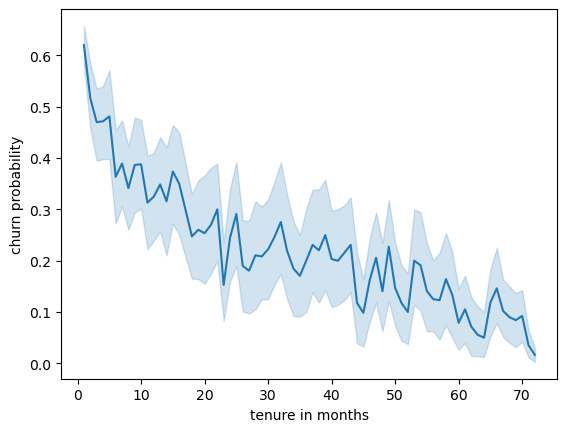

In [8]:
sns.lineplot(data=df, x='tenure', y='Churn_Yes')
plt.xlabel('tenure in months')
plt.ylabel('churn probability')
plt.show()

- It seems like a negative correlation-- the longer you are tenured, the lowere the probability of a churn.
- It doesn't seem linear, given the steep drop off from 0-10, and then steady decline afterwards

__3. Define X and y and split your data into Training and Test using an 80/20 split (you may consider setting a `random_state` for reproducibility)__

__Build the best model you can on the TRAINING set using a decision tree classifier.  Do a grid search over the hyperparameters `max_depth` and `min_samples_leaf`.  Use GridSearchCV with the following instructions:__
- search `max_depth` within the range of [2,15]
- search `min_samples_leaf` within the range [1,100] (in steps of 10)
- 5-fold CV
- use AUC as the `scoring` function ("roc_auc")

**Report the optimal values of the parameters `min_samples_leaf` and `max_depth` and the AUC associated with it. Define a model `tree_best` that uses your optimized value of `min_samples_leaf` and `max_depth` and fit it to the 80% training data.**

In [9]:
X = df.drop(columns=['Churn_Yes'])
y = df['Churn_Yes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

params = {'max_depth': range(2, 16), 'min_samples_leaf': range(1, 101, 10)}

tree = DecisionTreeClassifier(random_state=42)

grid = GridSearchCV(tree,param_grid=params,cv=5,scoring='roc_auc')

grid.fit(X_train, y_train)

print(f'best parameters: {grid.best_params_}')
print(f'best AUC: {round(grid.best_score_, 4)}')

best parameters: {'max_depth': 6, 'min_samples_leaf': 31}
best AUC: 0.8302


In [10]:
tree_best = DecisionTreeClassifier(max_depth=grid.best_params_['max_depth'], min_samples_leaf=grid.best_params_['min_samples_leaf'], random_state=42)

tree_best.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=6, min_samples_leaf=31, random_state=42)

**4. Calculate the feature importances.  For the top 5 most important features, explain whether you think they would be positively or negatively correlated with churn.**

In [11]:
importances = pd.Series(tree_best.feature_importances_,index=X_train.columns).sort_values(ascending=False)

print(importances.head(5))

tenure                                0.460471
InternetService_Fiber optic           0.321031
MonthlyCharges                        0.040081
PaymentMethod_Electronic check        0.038546
OnlineSecurity_No internet service    0.025372
dtype: float64


1. Tenure: as we saw, this one has a negative correlation with churn; the longer someone has stayed with the company the less likely they are to churn
2. Fiber optic-- I think that this will have a positive correlation with churn. Fiber optic is the most advanced/fastest/most expensive form of internet. At that price range and quality, I think that there will be more competition and customers paying that much would be more willing to swap to competitors for better service and/or lower prices.
3. Monthly charges should have a positive correlation with churn. The more expensive the internet bill is, the more likely a customer would want to switch.
4. Electronic check I think would also have a positive correlation with churn. Compared to a scheduled auto-payment from your bank, it is much quicker for customers to switch, by simply stopping the payment of their internet service.
5. No internet service-- this should have a negative correlation with churn, essentially for the opposite reasons of fiber optic. It's the simplest, most barebones, and cheapest form of play, so customers would be less likely to switch.

**5.  Now fit Lasso Regression (`LogisticRegression()` with `penalty = 'l1'`) to the Training set and use GridSearch or a for loop to find the best value of the hyperparameter C:  `C=[0.01,.1,.5,1,5,10,50,100]`.  Report on the optimal value of C.  Define a model `lr_best` that uses these parameters.**


In [12]:
lr = LogisticRegression(penalty='l1', solver='liblinear', max_iter=5000)

params = {'C': [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]}

grid_lr = GridSearchCV(lr, params, cv=5, scoring='roc_auc')

grid_lr.fit(X_train, y_train)

print(f'best c: {grid_lr.best_params_['C']}')
print(f'best AUC: {grid_lr.best_score_}')

best c: 50
best AUC: 0.8445690639500514


In [13]:
lr_best = LogisticRegression(penalty='l1', solver='liblinear', C=grid_lr.best_params_['C'], max_iter=5000)

lr_best.fit(X_train, y_train)


LogisticRegression(C=50, max_iter=5000, penalty='l1', solver='liblinear')

**6. Print the regularized coefficient values in `lr_best`.  How many of the Lasso coefficients have shrunken all the way to zero (use 4 decimal places)?  Interpret what you learn from these coefficients.**

In [14]:
coefficients = pd.Series(lr_best.coef_[0], index=X_train.columns).round(4)

print(coefficients)

SeniorCitizen                            0.1931
tenure                                  -0.0329
MonthlyCharges                          -0.0636
gender_Male                             -0.0186
Partner_Yes                             -0.0302
Dependents_Yes                          -0.2423
PhoneService_Yes                         1.2088
MultipleLines_No phone service           0.4557
MultipleLines_Yes                        0.6586
InternetService_Fiber optic              2.4923
InternetService_No                      -0.1811
OnlineSecurity_No internet service      -0.1857
OnlineSecurity_Yes                      -0.0864
OnlineBackup_No internet service        -0.1831
OnlineBackup_Yes                         0.1672
DeviceProtection_No internet service    -0.1873
DeviceProtection_Yes                     0.3675
TechSupport_No internet service         -0.1724
TechSupport_Yes                         -0.0386
StreamingTV_No internet service         -0.1801
StreamingTV_Yes                         

**7.  Use your toolbox!! Now pick a third classification model of your choice. You can use something we learned in class (SVM, MLPClassifier) or something else you maybe know of (kNN, RandomForest, Linear Discriminant).  Fit the model - you can use default hyperparameters (dont worry about optimizing) - and see how well it does (AUC).**


In [15]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_probs = rf.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_probs)

print(f'rf auc: {round(rf_auc, 4)}')

rf auc: 0.8139


__8. Using your TEST data plot the ROC Curves for each of the three models.  You will need to use the predicted probabilities from each model applied to the TEST set and the `roc_curve()` function - make sure to plot the three curves together on the same plot. The plot should have a legend.  Review the AUC values to identify the best of these three.  Which one is best? Call this `best_model`.__

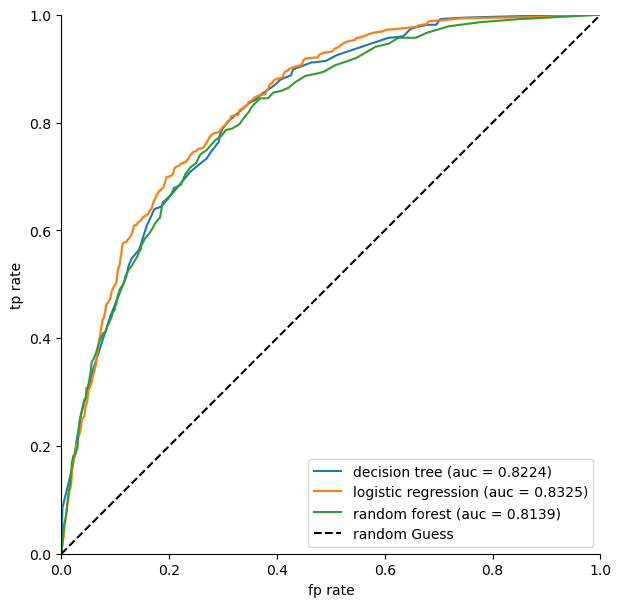

In [24]:
models = {
    'decision tree': tree_best,
    'logistic regression': lr_best,
    'random forest': rf
}

auc_scores = {}


fig, ax = plt.subplots(figsize=(7, 7))

for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)

    auc_scores[name] = auc

    sns.lineplot(x=fpr, y=tpr, ax=ax,
                 label=f'{name} (auc = {round(auc, 4)})')

# Random classifier reference
ax.plot([0, 1], [0, 1], 'k--', label='random Guess')

# Fix axes to bottom-left (0, 0)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect('equal')

ax.set_xlabel('fp rate')
ax.set_ylabel('tp rate')
ax.legend(loc='lower right')

sns.despine()
plt.show()


In [17]:
best = max(auc_scores, key=auc_scores.get)
best_model = models[best]

print(f'best auc: {best} @ {round(auc_scores[best], 4)}')

best auc: logistic regression @ 0.8325


__9. What is the cost / benefit matrix for implementing this model?  HINT: The cost is given in the problem description.  Remember that everyone who receives the offer takes it. The benefit comes when we make the offer to a customer whose actual Churn value is 1.  (i.e. they would have left us but we saved them).   We can assume each customer generates the same revenue - equal to the average of `MonthlyCharges`. Report the benefit as a YEARLY value.__

In [18]:
cost = 200
benefit = df['MonthlyCharges'].mean() * 12

print(f'yearly benefit: {round(benefit, 2)}')
print(f'net benefit: {round(benefit - cost, 2)}')

cost_benefit = pd.DataFrame(
    [[benefit - cost, -cost],
     [0, 0]],
    index=['Offer', 'No Offer'],
    columns=['Actual Churn', 'Actual No Churn']
)

cost_benefit

yearly benefit: 777.58
net benefit: 577.58


,Actual Churn,Actual No Churn
Offer,577.578498,-200
No Offer,0.000000,0


__10. Using `best_model` -  along with the cost/benefit matrix - now we want to look at profit.  Plot a *PROFIT CURVE* that shows the overall profit at different levels of marketing.  You'll need to sort the threshold probabilities, and calculate the profit at each threshold by determining who you market to and who you dont.  Use your cost/benefit numbers to calculate total profit at each threshold value. (You may want to refer back to the`T5_Model_assessment` notebook)__

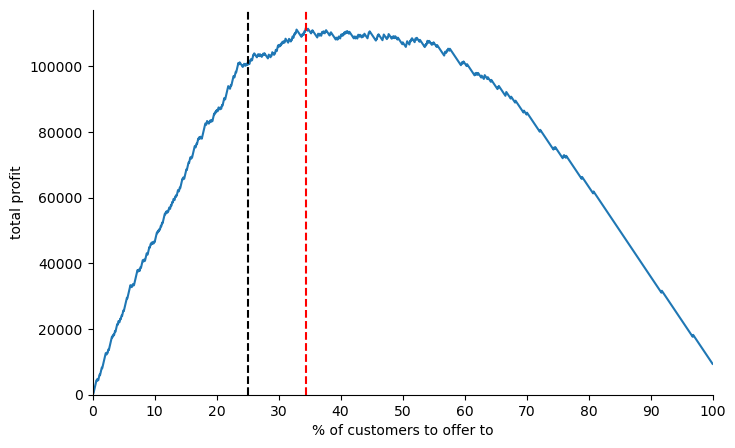

optimal: 111591.04 @ 34.4%
current: 100867.27 @ 25%
gap: 10723.77


In [73]:

probs = best_model.predict_proba(X_test)[:, 1]

order = np.argsort(probs)[::-1]
y_sorted = np.array(y_test)[order]

customers = np.arange(len(y_sorted) + 1)
tp = np.concatenate(([0], np.cumsum(y_sorted)))

profit = tp * benefit - customers * cost

percent = customers / len(y_sorted) * 100

index_max = np.argmax(profit)
index_25 = int(len(y_sorted) * 0.25)

profit_max = round(profit[index_max], 2)
profit_25 = round(profit[index_25], 2)

def get_fig(): # for reuse
    fig, ax = plt.subplots(figsize=(8, 5))

    sns.lineplot(x=percent, y=profit, ax=ax)

    ax.axvline(25, color='black', linestyle='--')
    ax.axvline(percent[index_max], color='red', linestyle='--')

    ax.set_xticks(np.arange(0, 101, 10))


    ax.set_xlim(0, 100)
    ax.set_ylim(bottom=0)

    ax.set_xlabel('% of customers to offer to')
    ax.set_ylabel('total profit')
    return fig, ax

fig, ax = get_fig()

sns.despine()
plt.show()


print(f'optimal: {profit_max} @ {round(percent[index_max], 2)}%')
print(f'current: {profit_25} @ 25%')
print(f'gap: {round(profit_max - profit_25, 2)}')


**11. Recall that Nadia told you there is only budget to market to the top 25% of customers.  Make a pitch to her for altering that decision based on your Profit curve.  How much do you recommend marketing to, and how much money will it make compared to her threshold?**

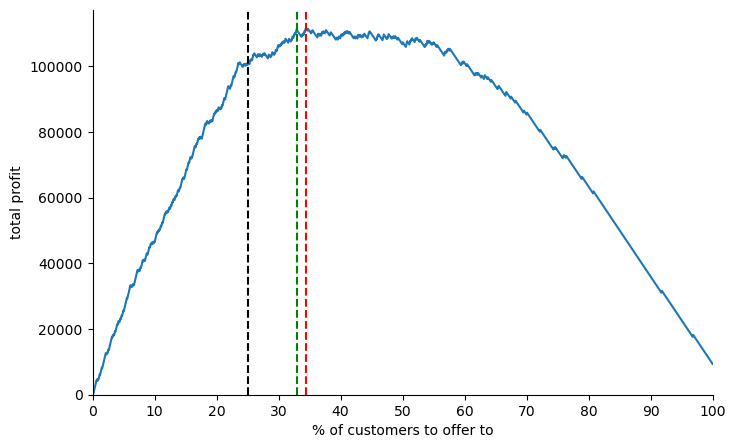

local: 111125.57 @ 32.91%
gap to optimal: 465.47
gap to 25%: 10258.3


In [75]:
# trying to find the ma right before 34.4%, it's an even smaller increase for a minimal 
index_max_local = np.argmax(profit[pct_marketed < 34])
profit_max_local = round(profit[index_max_local], 2)    

fig, ax = get_fig()
ax.axvline(percent[index_max_local], color='green', linestyle='--')
sns.despine()
plt.show()

print(f'local: {profit_max_local} @ {round(percent[index_max_local], 2)}%')
print(f'gap to optimal: {round(profit_max - profit_max_local, 2)}')
print(f'gap to 25%: {round(profit_max_local - profit_25, 2)}')

As we can see by the graph, 25% does catch the steepest growth in total profit and would net us $100,867.27 in profit. 

However, this hard cap still loses out on a significant profit, compared to a relatively small percentage increase to ~35%. The absolute maximum in the entire dataset is $111,591.04 at 34.4% which would be an increase of $10723.77, a jump of roughly 10% in profit. That said, there is another local maxima that's also a significant increase in profit at 32.91%, which still nets $111,125.57 and an increase in $10,258.30, only losing out on $465.47 of projected profit at a 2% lower budget.

I would propose to bump the budget up to 32.91%, which I consider a good comprimise of catching nearly all of the potential lost profit while only pushing up the budget up by ~7%, which would allow us to increase our simulated profits up by $10,258.30. The profit that we lose from not pushing the budget to the theoretical maximum is less than the value of a single retained customer, which is a loss I think is worth it if it makes it easier for upper management to accept the proposed budget raise.

__12. Assume Nadia was persuaded by your pitch and this model was deployed - and it performed as expected.  Now it is performance review season, and you are looking for a raise!!
Estimate the amount of money you made for the company by using your model.  Compare your profit above against a "dumb" model of marketing to the same amount of customers in the Test set who are selected randomly. (Hint: you can use a random number generator to pick customers at random to market to, and see what their profit would be).   Scale your results up to the overall consumer base of 100,000 customers to make your case.__

In [ ]:
target = index_max_local

rng = np.random.default_rng(42)

index_random = rng.choice(
    len(y_test), size=target, replace=False
)

random_tp = np.array(y_test)[index_random].sum()
random_profit = random_tp * benefit - target * cost

In [78]:
scale = 100000 / len(y_test)

model_scaled = profit_max_local * scale
random_scaled = random_profit * scale
gap_scaled = model_scaled - random_scaled

print(f'model profit: ${round(model_scaled, 2)}')
print(f'random profit: ${round(random_scaled, 2)}')
print(f'improvement: ${round(gap_scaled, 2)}')

model profit: $7898050.46
random profit: $-225904.24
improvement: $8123954.7


for the sake of the scenario, assuming that the final performance of the model was exactly the same as simulated

Overall, our model was able to generate a profit of $7,898,050.46 for the company, which comes out to a profit of roughly $79 per customer. Interestingly, the random model actually manages to lose money, generating a loss of -$225,904.24. This means that no only did our model generate a total benefit for the company of $8,123,954.70, this entire intiative would not have even been worth undertaking for the company, if it weren't for the existence of our model.

__13.  (Extra Credit):  In the above exercise we assumed the benefit of each customer was the same.  But it would be even better to incorporate each customer's individual spending in the cost/benefit!! Calculate an *individualized expected value* for profit/loss for _each customer_ using their specific Monthly Charges and their calculated probability of churn.    You'll need to calculate Expected Value for each customer (using the individualized Monthly Charges) and use the sorted Expected Value to draw the line of whom to market to - and to calculate profit.   Are the results any better?__